# 09 · Model 5 — PyTorch Temporal 1D-CNN (Convolutional Sequence Model)

**Idea:** In addition to recurrent networks (LSTMs), **1D Temporal Convolutional Networks (1D-CNNs)** offer a powerful alternative for sequence modeling. 

Instead of processing cycles step-by-step sequentially, 1D convolution filters slide across the time dimension to detect **local multi-sensor trends, sudden drifts, and wear patterns** simultaneously across all sensor channels.

Key advantages:
- **Parallel processing:** Computations across the sequence window run concurrently.
- **Hierarchical feature extraction:** Lower convolutional layers detect local fluctuations; deeper layers synthesize global engine degradation trends.

In [1]:
import os
os.environ.setdefault('MPLCONFIGDIR', '/tmp/matplotlib_cache')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from utils import (
    SEED, RUL_CAP, evaluate, compute_nasa_score, stage_table,
    plot_validation, plot_test, savefig,
    PROCESSED_DATA, MODELS, RESULTS
)

torch.manual_seed(SEED)
np.random.seed(SEED)
device = torch.device('cpu')
print('Using device:', device)

Using device: cpu


## 1. Load Preprocessed Sequence Tensors

We load the normalized sequence tensors from `data/processed/`.

In [2]:
X_train = np.load(PROCESSED_DATA / 'X_train_seq.npy')
y_train = np.load(PROCESSED_DATA / 'y_train_seq.npy')
y_raw_train = np.load(PROCESSED_DATA / 'y_raw_train_seq.npy')
u_train = np.load(PROCESSED_DATA / 'u_train_seq.npy')

X_val = np.load(PROCESSED_DATA / 'X_val_seq.npy')
y_val = np.load(PROCESSED_DATA / 'y_val_seq.npy')
y_raw_val = np.load(PROCESSED_DATA / 'y_raw_val_seq.npy')
u_val = np.load(PROCESSED_DATA / 'u_val_seq.npy')

X_test = np.load(PROCESSED_DATA / 'X_test_seq.npy')
y_test = np.load(PROCESSED_DATA / 'y_test_seq.npy')
y_raw_test = np.load(PROCESSED_DATA / 'y_raw_test_seq.npy')

train_loader = DataLoader(
    TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train)),
    batch_size=64, shuffle=True
)
val_loader = DataLoader(
    TensorDataset(torch.from_numpy(X_val), torch.from_numpy(y_val)),
    batch_size=128, shuffle=False
)

print(f'Train dataset: {len(X_train):,} sequences')
print(f'Val dataset:   {len(X_val):,} sequences')
print(f'Test dataset:  {len(X_test)} engine sequences')

Train dataset: 14,241 sequences
Val dataset:   3,490 sequences
Test dataset:  100 engine sequences


## 2. Define the Temporal 1D-CNN Architecture

PyTorch `nn.Conv1d` expects tensor input of shape `(batch_size, in_channels, seq_len)`. We transpose the input tensor `(batch_size, 30, 14)` $\rightarrow$ `(batch_size, 14, 30)`.

Architecture:
- **Block 1:** `Conv1d(14, 32, kernel_size=5, padding=2)` + `BatchNorm1d` + `ReLU`
- **Block 2:** `Conv1d(32, 64, kernel_size=5, padding=2)` + `BatchNorm1d` + `ReLU` + `MaxPool1d(2)`
- **Block 3:** `Conv1d(64, 128, kernel_size=3, padding=1)` + `BatchNorm1d` + `ReLU`
- **Global Pooling:** `AdaptiveAvgPool1d(1)` $\rightarrow$ extracts fixed 128-dimensional latent degradation vector
- **Dense Head:** `Linear(128, 64)` $\rightarrow$ `ReLU` $\rightarrow$ `Dropout(0.2)` $\rightarrow$ `Linear(64, 1)`

In [3]:
class TemporalCNNRegressor(nn.Module):
    def __init__(self, in_channels=14, dropout=0.2):
        super().__init__()
        self.conv_net = nn.Sequential(
            nn.Conv1d(in_channels, 32, kernel_size=5, padding=2),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.Conv1d(32, 64, kernel_size=5, padding=2),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.MaxPool1d(2),
            nn.Conv1d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.AdaptiveAvgPool1d(1)
        )
        self.fc = nn.Sequential(
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        # x is (batch, seq_len, in_channels) -> transpose to (batch, in_channels, seq_len)
        x = x.transpose(1, 2)
        feats = self.conv_net(x).squeeze(-1)
        return self.fc(feats).squeeze(-1)

model = TemporalCNNRegressor(in_channels=14, dropout=0.2).to(device)
print(model)
num_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Total trainable parameters: {num_params:,}')

TemporalCNNRegressor(
  (conv_net): Sequential(
    (0): Conv1d(14, 32, kernel_size=(5,), stride=(1,), padding=(2,))
    (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv1d(32, 64, kernel_size=(5,), stride=(1,), padding=(2,))
    (4): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Conv1d(64, 128, kernel_size=(3,), stride=(1,), padding=(1,))
    (8): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (9): ReLU()
    (10): AdaptiveAvgPool1d(output_size=1)
  )
  (fc): Sequential(
    (0): Linear(in_features=128, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=64, out_features=1, bias=True)
  )
)
Total trainable parameters: 46,049


## 3. Train the Model with Early Stopping & LR Scheduling

We use `SmoothL1Loss` (Huber Loss) and `AdamW` optimizer with learning rate decay.

In [4]:
criterion = nn.SmoothL1Loss()
optimizer = torch.optim.AdamW(model.parameters(), lr=0.002, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=3)

train_losses, val_losses = [], []
best_val_loss = float('inf')
best_weights = None
patience = 8
patience_counter = 0

print('Starting 1D-CNN training...')
for epoch in range(1, 35):
    # Training phase
    model.train()
    running_train_loss = 0.0
    for bx, by in train_loader:
        bx, by = bx.to(device), by.to(device)
        optimizer.zero_grad()
        preds = model(bx)
        loss = criterion(preds, by)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        running_train_loss += loss.item() * len(by)
    train_loss = running_train_loss / len(train_loader.dataset)
    train_losses.append(train_loss)

    # Validation phase
    model.eval()
    running_val_loss = 0.0
    with torch.no_grad():
        for bx, by in val_loader:
            bx, by = bx.to(device), by.to(device)
            preds = model(bx)
            loss = criterion(preds, by)
            running_val_loss += loss.item() * len(by)
    val_loss = running_val_loss / len(val_loader.dataset)
    val_losses.append(val_loss)

    scheduler.step(val_loss)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_weights = model.state_dict().copy()
        patience_counter = 0
    else:
        patience_counter += 1
        if patience_counter >= patience:
            print(f'Early stopping triggered at epoch {epoch}')
            break

    if epoch % 5 == 0 or epoch == 1:
        print(f'Epoch {epoch:2d}/35 | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | LR: {optimizer.param_groups[0]["lr"]:.6f}')

model.load_state_dict(best_weights)
torch.save(model.state_dict(), MODELS / 'cnn_model.pt')
print('Best 1D-CNN weights saved to outputs/models/cnn_model.pt')

Starting 1D-CNN training...
Epoch  1/35 | Train Loss: 28.8769 | Val Loss: 12.8384 | LR: 0.002000
Epoch  5/35 | Train Loss: 9.7494 | Val Loss: 21.3649 | LR: 0.001000
Epoch 10/35 | Train Loss: 7.9904 | Val Loss: 12.6646 | LR: 0.001000
Epoch 15/35 | Train Loss: 7.0950 | Val Loss: 13.3202 | LR: 0.000500
Epoch 20/35 | Train Loss: 6.7929 | Val Loss: 12.2214 | LR: 0.000250
Early stopping triggered at epoch 24
Best 1D-CNN weights saved to outputs/models/cnn_model.pt


## 4. Training Loss Curve

Let's plot the training and validation loss curves.

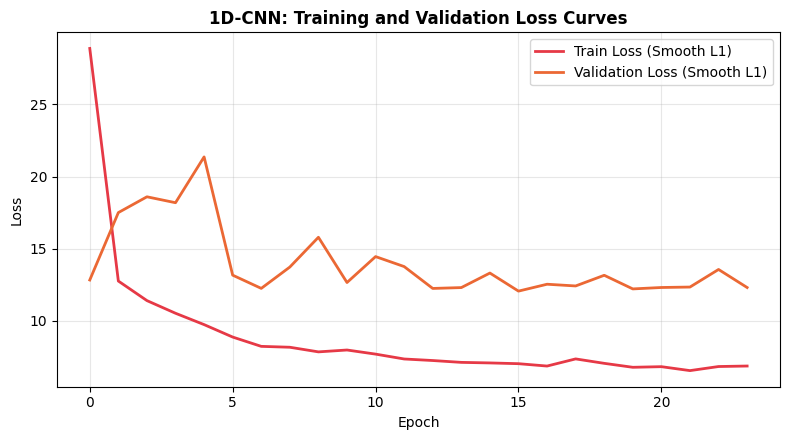

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(train_losses, label='Train Loss (Smooth L1)', color='#e63946', lw=2)
ax.plot(val_losses, label='Validation Loss (Smooth L1)', color='#eb6834', lw=2)
ax.set_title('1D-CNN: Training and Validation Loss Curves', fontsize=12, fontweight='bold')
ax.set_xlabel('Epoch')
ax.set_ylabel('Loss')
ax.legend()
ax.grid(True, alpha=0.3)
savefig('09_cnn_training_loss')

## 5. Validation Performance & Early vs Late Life Analysis

We evaluate the 1D-CNN on all cycles of the 20 validation engines.

In [6]:
model.eval()
with torch.no_grad():
    val_preds = model(torch.from_numpy(X_val).to(device)).cpu().numpy()

val_metrics = evaluate(y_val, val_preds)
print('1D-CNN Validation Metrics:', val_metrics)

# Save validation predictions
val_df_out = pd.DataFrame({'unit': u_val, 'RUL': y_val, 'predicted': val_preds, 'RUL_raw': y_raw_val})
val_df_out.to_csv(RESULTS / 'cnn_val_predictions.csv', index=False)

st_table = stage_table(y_raw_val, y_val, val_preds)
print('\nEarly vs Late Life Performance (Validation):')
print(st_table)

1D-CNN Validation Metrics: {'RMSE': 17.31, 'MAE': 12.81, 'R2': 0.828}

Early vs Late Life Performance (Validation):
                   Rows   RMSE    MAE
Stage                                
early (RUL > 100)  1470  16.01  11.97
late (RUL ≤ 100)   2020  18.20  13.41


### Validation Diagnostics Plot

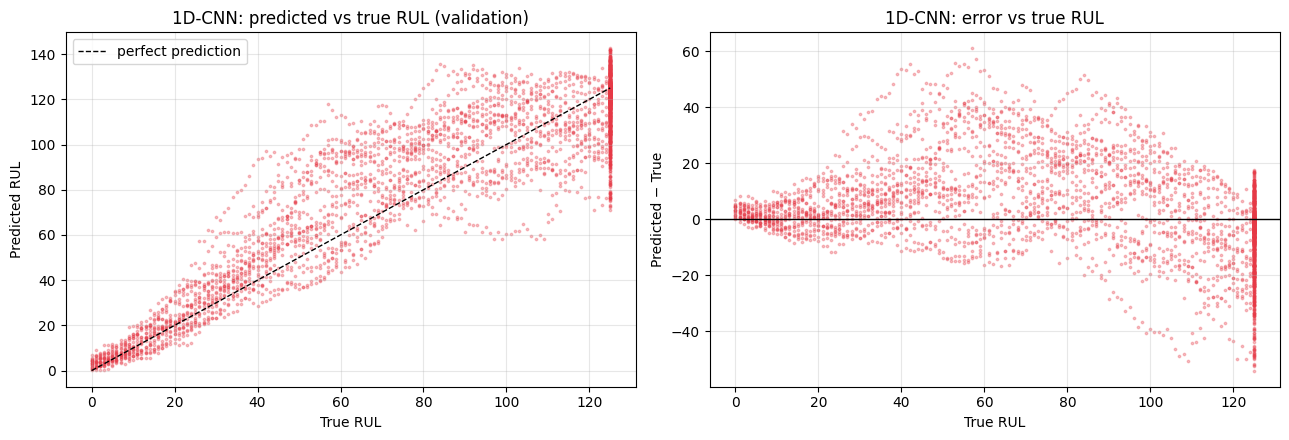

In [7]:
plot_validation('1D-CNN', y_val, val_preds, '09_cnn_val_diagnostic')

## 6. Official NASA Test Set Performance (100 Engines)

Each of the 100 test engines is predicted using its final 30-cycle sensor sequence.

1D-CNN Official Test Set Results:
  Test RMSE:   18.93 cycles
  Test MAE:    13.3 cycles
  Test R²:     0.777
  NASA Score:  1404.26


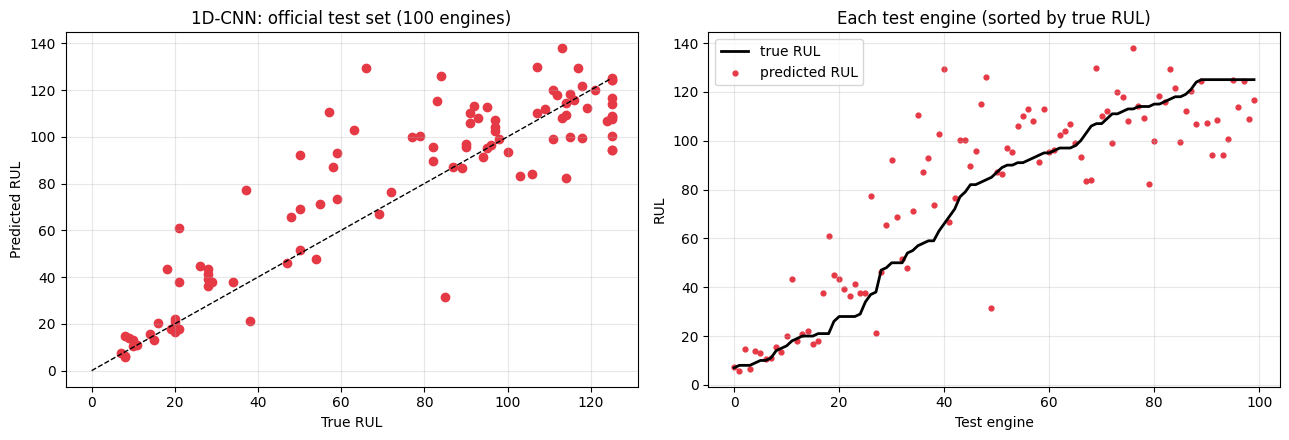

In [8]:
with torch.no_grad():
    test_preds = model(torch.from_numpy(X_test).to(device)).cpu().numpy()

test_metrics = evaluate(y_test, test_preds)
test_nasa_score = compute_nasa_score(y_test, test_preds)

print('1D-CNN Official Test Set Results:')
print(f'  Test RMSE:   {test_metrics["RMSE"]} cycles')
print(f'  Test MAE:    {test_metrics["MAE"]} cycles')
print(f'  Test R²:     {test_metrics["R2"]}')
print(f'  NASA Score:  {test_nasa_score:.2f}')

# Save test predictions
test_df_out = pd.DataFrame({'unit': range(1, 101), 'RUL': y_test, 'predicted': test_preds, 'RUL_raw': y_raw_test})
test_df_out.to_csv(RESULTS / 'cnn_test_predictions.csv', index=False)

plot_test('1D-CNN', y_test, test_preds, '09_cnn_test_scatter')